# 07b. Visualisasi Ruang Embedding: Hari Volatilitas Tinggi vs Rendah

Embedding FinBERT harian yang dipakai Model C (`c2_finbert_art_cls.npy`: judul+lead per artikel, pooling [CLS], rata-rata per hari).
Volatilitas diukur dari besar return hari berikutnya |r(t+1)|: 20% hari terbesar = tinggi, 20% terkecil = rendah (hanya hari yang punya berita).
Selain plot t-SNE, pemisahan diuji secara kuantitatif di ruang 768 dimensi (5-NN kosinus dan silhouette), karena t-SNE saja bisa menipu.

In [1]:
from c_common import *
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

D, text = load_all()
ANALYSIS = RESULTS_C / "analysis"
ANALYSIS.mkdir(exist_ok=True)
TITLE, LEAD = "judul_gabungan", "lead_paragraph_gabungan"
has_news = ((text[TITLE].fillna("") + ". " + text[LEAD].fillna("")).str.strip(" .").str.len() > 0).values
emb = pd.DataFrame(np.load(FEATURES_C / "c2_finbert_art_cls.npy"), index=text.index)
print(emb.shape, "| hari dengan berita:", int(has_news.sum()))

(1202, 768) | hari dengan berita: 1182


In [2]:
semua = pd.concat([D[s].assign(split=s) for s in ["train", "val", "test"]])
semua = semua[semua["date"].isin(text.index[has_news])].copy()
semua["abs_r"] = semua["target_ret"].abs()
q_lo, q_hi = semua["abs_r"].quantile([0.2, 0.8])
semua["volatilitas"] = np.where(semua["abs_r"] >= q_hi, "tinggi", np.where(semua["abs_r"] <= q_lo, "rendah", "tengah"))
pilih = semua[semua["volatilitas"] != "tengah"].reset_index(drop=True)
print("hari berita:", len(semua), "| ambang |r| rendah <=", round(q_lo, 5), "| tinggi >=", round(q_hi, 5))
print(pilih.groupby("split")["volatilitas"].value_counts().unstack())

hari berita: 1160 | ambang |r| rendah <= 0.00066 | tinggi >= 0.00385
volatilitas  rendah  tinggi
split                      
test             32      23
train           166     174
val              35      35


In [3]:
X = emb.loc[pilih["date"]].values
X = X / np.linalg.norm(X, axis=1, keepdims=True)
yv = (pilih["volatilitas"] == "tinggi").astype(int).values
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
knn = KNeighborsClassifier(5, metric="cosine")
acc = cross_val_score(knn, X, yv, cv=skf, scoring="balanced_accuracy")
rng = np.random.default_rng(SEED)
acak = [cross_val_score(knn, X, rng.permutation(yv), cv=skf, scoring="balanced_accuracy").mean() for _ in range(30)]
sil = float(silhouette_score(X, yv, metric="cosine"))
hasil = {"n_tinggi": int(yv.sum()), "n_rendah": int((1 - yv).sum()), "ambang_rendah": float(q_lo), "ambang_tinggi": float(q_hi),
         "knn5_balanced_acc": float(acc.mean()), "knn5_per_fold": [round(float(v), 3) for v in acc],
         "knn5_label_acak_mean": float(np.mean(acak)), "knn5_label_acak_p95": float(np.percentile(acak, 95)),
         "silhouette_cosine": sil}
for k, v in hasil.items():
    print(f"{k:22s} {v}")

n_tinggi               232
n_rendah               233
ambang_rendah          0.0006593736189746
ambang_tinggi          0.00385025843061188
knn5_balanced_acc      0.5090656799259945
knn5_per_fold          [0.504, 0.462, 0.504, 0.582, 0.494]
knn5_label_acak_mean   0.5061424606845513
knn5_label_acak_p95    0.5388344125809436
silhouette_cosine      -0.0003268539148848504


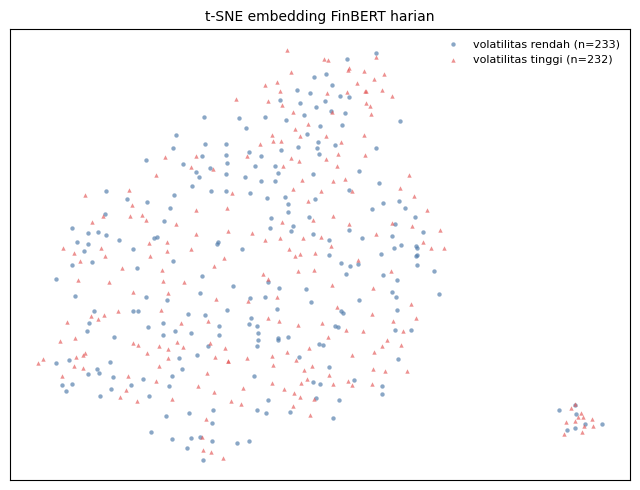

In [4]:
Z = TSNE(2, perplexity=30, init="pca", random_state=SEED, metric="cosine").fit_transform(X)
pilih["tsne_x"], pilih["tsne_y"] = Z[:, 0], Z[:, 1]
fig, ax = plt.subplots(figsize=(6.5, 5))
for g, c, mk in [("rendah", "#4C78A8", "o"), ("tinggi", "#E45756", "^")]:
    m = (pilih["volatilitas"] == g).values
    ax.scatter(Z[m, 0], Z[m, 1], s=10, c=c, marker=mk, alpha=0.65, linewidths=0, label=f"volatilitas {g} (n={m.sum()})")
ax.set_xticks([]); ax.set_yticks([]); ax.legend(fontsize=8, frameon=False)
ax.set_title("t-SNE embedding FinBERT harian", fontsize=10)
plt.tight_layout(); plt.savefig(ANALYSIS / "tsne_volatilitas.png", dpi=150); plt.show()

In [5]:
# Gugus kecil yang terpisah di plot: hari apa saja? (untuk cek apakah gugus itu soal volatilitas atau soal isi/jumlah berita)
from sklearn.cluster import DBSCAN
lbl = DBSCAN(eps=4, min_samples=5).fit_predict(Z)
ukuran = pd.Series(lbl).value_counts()
kecil = [k for k in ukuran.index if k != -1 and ukuran[k] < 0.1 * len(Z)]
for k in kecil:
    g = pilih[lbl == k]
    print(f"gugus {k}: {len(g)} hari | porsi tinggi {(g['volatilitas']=='tinggi').mean():.2f} | median jumlah berita {g['jumlah_berita'].median()}")
    print("   contoh judul:", [str(text.loc[d, TITLE]).split(" | ")[0][:80] for d in g["date"].head(3)])

gugus 1: 19 hari | porsi tinggi 0.63 | median jumlah berita 29.0
   contoh judul: ['Russian forces invade Ukraine', "Kelly Evans: The most important thing that's happened in recent weeks", "Taiwan slams Elon Musk, says it's 'not for sale' nor part of China"]


In [6]:
pilih[["date", "split", "target_ret", "abs_r", "volatilitas", "jumlah_berita", "tsne_x", "tsne_y"]].to_csv(ANALYSIS / "tsne_volatilitas.csv", index=False)
(ANALYSIS / "tsne_volatilitas_ringkasan.json").write_text(json.dumps(hasil, indent=2))
print("tersimpan di", ANALYSIS)

tersimpan di ..\results_c\analysis


## Kesimpulan

Hari bervolatilitas tinggi dan rendah bercampur di plot t-SNE, dan di ruang 768 dimensi 5-NN tidak lebih baik dari label acak (silhouette ≈ 0).
Embedding FinBERT harian lebih menangkap topik berita daripada besar reaksi pasar keesokan harinya.